# Visual Question Answering, Report Generation, and Anatomy Localization with MedGemma 1.5
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/f10409/MedGemma_demo/blob/main/1_medgemma_demo.ipynb)

In this notebook, you use MedGemma 1.5 on chest X-rays (CXR) for three tasks:
1. **Visual question answering (VQA):** ask a question about an image, for example "Is there pleural effusion in this image?" We also use yes/no questions to classify 4 conditions.
2. **Report generation:** the model writes the findings of a report. You compare them with the radiologist's findings.
3. **Anatomy localization:** the model gives a box around a body part, for example the right lung.

All tasks are **zero-shot**: the model gets no examples and no extra training.

Links: [Model card](https://huggingface.co/google/medgemma-1.5-4b-it) · [Developer site](https://developers.google.com/health-ai-developer-foundations/medgemma) · [MedGemma paper](https://arxiv.org/abs/2507.05201) · [MedGemma 1.5 paper](https://arxiv.org/abs/2604.05081)

<img src="https://raw.githubusercontent.com/f10409/MedGemma_demo/main/notebook_figs/medgemma_overview0.png" alt="overview" width="750"> <br>

### What is new in MedGemma 1.5?
- There is only a **4B** model (4 billion parameters).
- It is much better at anatomy localization.

## Step 1: Select a GPU and Download the Data
1. Select a GPU: **Runtime → Change runtime type → T4 GPU**. Do this before you run any cell. If you change the runtime later, Colab deletes the downloaded data.
2. Run the next cell. It gets the helper code from GitHub. Then it downloads the free **Open-i chest X-ray dataset** from Indiana University: 7,470 images and 3,955 reports ([source](https://openi.nlm.nih.gov/faq)).

The download (about 1.4 GB) takes a few minutes. While it runs, do Step 2. If the data is already there, the cell skips the download.

In [ ]:
import os
import sys

IN_COLAB = "google.colab" in sys.modules

# ---- 1. Get the helper code (utils/) from GitHub (Colab only)
if IN_COLAB:
    if not os.path.exists("/content/MedGemma_demo"):
        !git clone -q https://github.com/f10409/MedGemma_demo.git /content/MedGemma_demo
    %cd /content/MedGemma_demo

# ---- 2. Download Open-i
from utils.openi_data import download_openi

DATA_DIR = download_openi("data/OpenI-IU-CXR")

✅ Open-i data ready: data/OpenI-IU-CXR


## Step 2: Get Access to MedGemma 1.5
You need permission to download MedGemma 1.5. Do these 4 parts on the Hugging Face website and in Colab. You do them only once.

1. Log in to Hugging Face (or sign up). Open the [MedGemma 1.5 page](https://huggingface.co/google/medgemma-1.5-4b-it) and accept the terms.<br>
<img src="https://raw.githubusercontent.com/f10409/MedGemma_demo/main/notebook_figs/HF_login.png" alt="login" width="750"><br>
2. Open your [token settings](https://huggingface.co/settings/tokens). Create a token of type **Read**.<br>
<img src="https://raw.githubusercontent.com/f10409/MedGemma_demo/main/notebook_figs/HF_access0.png" alt="access0" width="750"><br>
<img src="https://raw.githubusercontent.com/f10409/MedGemma_demo/main/notebook_figs/HF_access1.png" alt="access1" width="750"><br>
3. Copy the token.<br>
<img src="https://raw.githubusercontent.com/f10409/MedGemma_demo/main/notebook_figs/HF_token.png" alt="token" width="500"><br>
4. Save the token in Colab:
   - In the left sidebar, click the 🔑 **Secrets** icon.
   - Click **Add new secret**. Name: `HF_TOKEN`. Value: your token.
   - Turn on **Notebook access**.

   Not on Colab? Skip part 4. Run `hf auth login` in a terminal, or run `from huggingface_hub import login; login()` in a new cell.

## Step 3: Setup
When the download in Step 1 is done and you finish Step 2, run the next cell. It installs the packages and imports the libraries. Then it checks the GPU, your Hugging Face token, and your access to MedGemma 1.5. If Colab asks for access to `HF_TOKEN`, click **Grant access**.

If a check fails, the error message tells you what to do. Fix it, then run the cell again.

> pip may show "ERROR: pip's dependency resolver ..." with a list of packages. This is only a warning. You can ignore it.

In [1]:
# ---- 1. Install RadHarmony and the other packages (Colab only)
if IN_COLAB:
    # RadHarmony loads the dataset. --no-deps keeps the Colab packages unchanged,
    # so we install only the RadHarmony packages that Open-i needs.
    !pip install -q --no-deps git+https://github.com/f10409/RadHarmony.git
    !pip install -q "monai<1.6" pydicom "transformers>=4.56"

# ---- 2. Import the libraries
import warnings

import torch
import transformers
from transformers import pipeline
from PIL import Image

# Dataset loading
from radharmony.harmonizer.openi_cxr import OpenICXRHarmonizer
from radharmony.dataset import OpenICXRDataset

# Utilities
from tqdm import tqdm
from utils.binary_metrics import binary_metrics, yes_rate_table
from utils.localization import draw_boxes, localization_prompt, pad_to_square, parse_boxes, remove_thinking
from utils.display_prediction import display_prediction
from utils.display_report import display_report
from utils.hf_token import check_hf_token, check_model_access
from utils.openi_data import CLASS_NAMES, add_findings_and_indication, select_cohort, sample_to_example
from utils.preprocess import preprocess
from utils.print_prompt import print_prompt
from utils.report import extract_findings
from utils.vqa import run_yes_no

# ---- 3. Check the GPU
assert torch.cuda.is_available(), "No GPU found. In Colab: Runtime → Change runtime type → T4 GPU."
print(f"GPU: {torch.cuda.get_device_name(0)}")

# ---- 4. Check the Hugging Face token and the access to MedGemma 1.5
check_hf_token(IN_COLAB)
check_model_access("google/medgemma-1.5-4b-it")

GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition
✅ Hugging Face token found
✅ You have access to google/medgemma-1.5-4b-it


## Step 4: Data Preparation
The next cell:
1. Reads the reports with [RadHarmony](https://f10409.github.io/RadHarmony/) and makes a table. Each row is one image, with its view (frontal or lateral), report, and labels.
2. Selects 100 frontal images: 20 for each class (No Finding, Atelectasis, Cardiomegaly, Consolidation, and Pleural Effusion).
3. Makes a list of samples with the RadHarmony dataset. Each sample has the image file path, the labels, and the report. We open the images later, when we make the prompts. We also add the findings and the indication from the table, for report generation.

In [2]:
# ---- 1. Harmonize with RadHarmony
harmonizer = OpenICXRHarmonizer(base_dir=DATA_DIR)

with warnings.catch_warnings():
    warnings.simplefilter(
        "ignore"
    )  # We did not download the DICOM files (75 GB), so DICOM warnings are expected
    df_all = harmonizer.harmonize()

print(f"Harmonized table: {df_all.shape[0]} images, {df_all.shape[1]} columns")
display(
    df_all[["patient_id", "image_path", "view_position", "report", *CLASS_NAMES]].head()
)

# ---- 2. Select a balanced sample
meta = select_cohort(df_all, n_per_class=20, seed=5656)
print("\nImages per class in the sample:")
display(meta.Pathology.value_counts())


# ---- 3. Load the samples with the RadHarmony dataset
def keep_path(sample):
    """Return the sample unchanged, so "img" stays an image file path."""
    return sample


dataset = OpenICXRDataset(
    base_image_dir=DATA_DIR,
    harmonized_df=meta,
    transform=keep_path,
    output_cls=True,
    output_report=True,
    cache_dir=None,
)
samples_eval = dataset.get_datasets()

# Convert the samples to the dicts that we use in the prompts
examples_eval = [sample_to_example(s, dataset.LABEL_COLS) for s in samples_eval]
examples_eval = add_findings_and_indication(examples_eval, samples_eval, meta, DATA_DIR)
print(f"Images in the sample: {len(examples_eval)}")

print("\nRaw RadHarmony sample:")
print(samples_eval[0])
print("\nConverted example (used in the prompts):")
print(examples_eval[0])

Harmonized table: 7470 images, 18 columns


,patient_id,image_path,view_position,report,no_finding,atelectasis,cardiomegaly,consolidation,pleural_effusion
0,CXR1,images/CXR1_1_IM-0001-3001.png,FRONTAL,The cardiac silhouette and mediastinum size ar...,1.0,0.0,0.0,0.0,0.0
1,CXR1,images/CXR1_1_IM-0001-4001.png,LATERAL,The cardiac silhouette and mediastinum size ar...,1.0,0.0,0.0,0.0,0.0
2,CXR2,images/CXR2_IM-0652-1001.png,FRONTAL,Borderline cardiomegaly. Midline sternotomy XX...,0.0,0.0,1.0,0.0,0.0
3,CXR2,images/CXR2_IM-0652-2001.png,LATERAL,Borderline cardiomegaly. Midline sternotomy XX...,0.0,0.0,1.0,0.0,0.0
4,CXR3,images/CXR3_IM-1384-1001.png,FRONTAL,"No displaced rib fractures, pneumothorax, or p...",1.0,0.0,0.0,0.0,0.0



Images per class in the sample:


Pathology
No Finding          20
Atelectasis         20
Cardiomegaly        20
Consolidation       20
Pleural Effusion    20
Name: count, dtype: int64

Images in the sample: 100

Raw RadHarmony sample:
{'img': 'data/OpenI-IU-CXR/images/CXR1851_IM-0553-1001.png', 'cls': [0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0], 'report': 'Heart size is normal. No focal airspace consolidations. No pneumothorax or effusion. No acute osseous findings. No acute cardiopulmonary findings. .'}

Converted example (used in the prompts):
{'ImagePath': 'data/OpenI-IU-CXR/images/CXR1851_IM-0553-1001.png', 'Pathology': 'No Finding', 'Report': 'Heart size is normal. No focal airspace consolidations. No pneumothorax or effusion. No acute osseous findings. No acute cardiopulmonary findings. .', 'Findings': 'Heart size is normal. No focal airspace consolidations. No pneumothorax or effusion. No acute osseous findings.', 'Indication': 'XXXX-year-old male with XXXX and dyspnea.'}


## Step 5: Load MedGemma 1.5
We load the model with the Hugging Face [`pipeline`](https://huggingface.co/docs/transformers/en/main_classes/pipelines). A pipeline puts all the steps to use a model into one function:
1. It changes your input (text and images) into numbers that the model can read.
2. It runs the model.
3. It changes the model output back into text.

We use the `"image-text-to-text"` pipeline, because the input is an image and text, and the output is text. Example: `pipe(text=messages)` gives the model's answer to `messages`.

In [3]:
# Load the MedGemma 1.5 model
model_id = "google/medgemma-1.5-4b-it"
print("🔄 Loading MedGemma 1.5 model...")

transformers.logging.set_verbosity_error()  # Hide repeated generation warnings

# Simple API: https://huggingface.co/docs/transformers/en/main_classes/pipelines
try:
    pipe = pipeline(
        "image-text-to-text",
        model=model_id,
        dtype=torch.bfloat16,
        device="cuda",
    )

    # Configure for deterministic output (greedy decoding)
    pipe.model.generation_config.do_sample = False
    print("✅ MedGemma 1.5 model loaded successfully!")

except Exception as e:
    print(f"❌ Error loading model: {str(e)}")
    print(
        "💡 Check that you accepted the model terms (Step 2, part 1) and that a GPU is selected (Step 1)."
    )
    raise

🔄 Loading MedGemma 1.5 model...


Loading weights:   0%|          | 0/883 [00:00<?, ?it/s]

✅ MedGemma 1.5 model loaded successfully!


## Step 6: Visual Question Answering (VQA)
In VQA, you ask a question about an image, and the model answers. For example: "Is there pleural effusion in this image?"

This is **zero-shot**: the model gets only the question, with no extra training. So the results show what the model already knows.

#### Prompt Format
We give the prompt to the model as a list of messages. Each message has a role:
```json
[
  {
    "role": "system",
    "content": "You are an expert radiologist."
  },
  {
    "role": "user",
    "content": [
      {"type": "image", "image": "..."},
      {"type": "text", "text": "Is there pleural effusion in this image? ..."}
    ]
  }
]
```
- **System prompt:** tells the model its role, for example "You are an expert radiologist." It applies to the full conversation.
- **User prompt:** the task and the input (the image and the text).

### VQA Example
We use the prompt from the MedGemma papers ([MedGemma](https://arxiv.org/abs/2507.05201), Table A7; [MedGemma 1.5](https://arxiv.org/abs/2604.05081), Table 8):
- **The question:** "Is there {condition} in this image?"
- **The answer format:** after the question, we add `You MUST end your response with either "Final Answer: yes" or "Final Answer: no"`. Then code can read the answer easily.
- **Image first,** then the text.
- **Greedy decoding:** the model always picks the most likely next token (a word or a part of a word). So you get the same answer each time.

We also add the system prompt "You are an expert radiologist.", as Google's [quick-start notebook](https://github.com/Google-Health/medgemma/blob/main/notebooks/quick_start_with_hugging_face.ipynb) does. The papers use no system prompt.

The next cell:
1. Makes the prompt for one image and shows it.
2. Runs the model and shows the answer.

CONVERSATION PROMPT

[SYSTEM]
----------------------------------------
You are an expert radiologist.

[USER]
----------------------------------------
  📷 PIL Image - Mode: RGB, Size: 512x420


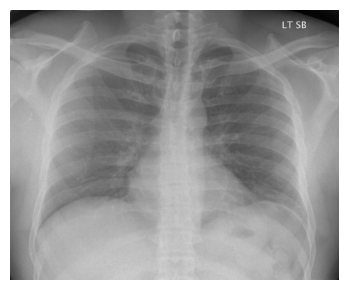

Is there atelectasis in this image? You MUST end your response with either "Final Answer: yes" or "Final Answer: no"

🔄 Running zero-shot prediction...
Question: Is there atelectasis?
Model response: Final Answer: yes
True pathology: Atelectasis


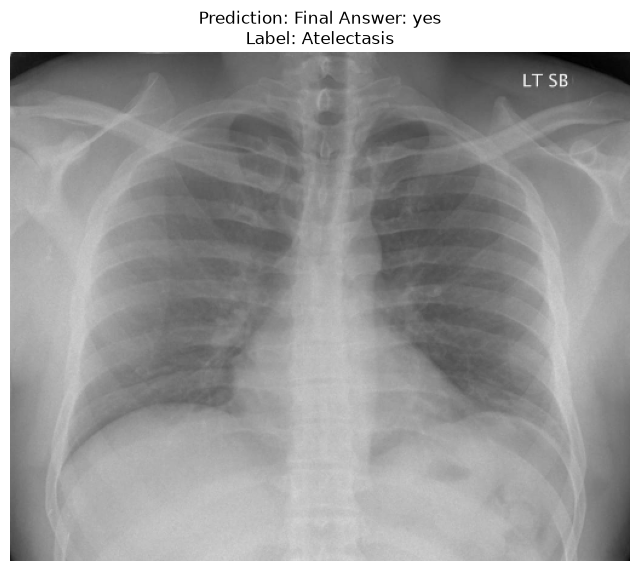

In [4]:
# ---- 1. Make the prompt
# System prompt for all tasks in this notebook
SYSTEM_MESSAGE = {
    "role": "system",
    "content": [{"type": "text", "text": "You are an expert radiologist."}],
}

# Class name -> condition name in the question
CONDITIONS = {
    "Atelectasis": "atelectasis",
    "Cardiomegaly": "cardiomegaly",
    "Consolidation": "consolidation",
    "Pleural Effusion": "pleural effusion",
}

# Answer format from the MedGemma 1.5 report (Table 8)
ANSWER_FORMAT = (
    'You MUST end your response with either "Final Answer: yes" or "Final Answer: no"'
)


class ZeroShotPrompt:
    """Zero-shot yes/no prompting for one condition in a CXR"""

    def format_prompt(self, condition, prompt=None):
        """Create the question for one condition"""
        if prompt is not None:
            return prompt
        return f"Is there {CONDITIONS[condition]} in this image? {ANSWER_FORMAT}"

    def format_data(self, example, condition, prompt=None):
        """Format one example and one condition for the model"""
        return [
            SYSTEM_MESSAGE,
            {
                "role": "user",
                "content": [
                    {
                        "type": "image",
                        "image": preprocess(Image.open(example["ImagePath"])),
                    },
                    {"type": "text", "text": self.format_prompt(condition, prompt)},
                ],
            },
        ]


zeroshot = ZeroShotPrompt()

# Select an example, and ask about its own class (or Cardiomegaly for a No Finding image)
example = examples_eval[56]
condition = (
    example["Pathology"] if example["Pathology"] in CONDITIONS else "Cardiomegaly"
)

messages = zeroshot.format_data(example, condition)
print_prompt(messages)

# ---- 2. Run the model
print("🔄 Running zero-shot prediction...")

output = pipe(
    text=messages,  # Structured prompt with system + user messages
    max_new_tokens=200,  # The model may write a short argument before the final answer
    return_full_text=False,  # Return only generated text, not input prompt
)

print(f"Question: Is there {CONDITIONS[condition]}?")
print(f"Model response: {output[0]['generated_text'].strip()}")
print(f"True pathology: {example['Pathology']}")

# Display the prediction with image
display_prediction(output, example, figsize=(8, 8))

### Try your own prompt and other examples
You can also ask other kinds of questions, not only yes/no questions. Change the prompt and run it again. For example:
- "What abnormal findings do you see in this chest X-ray?"
- "Describe the size and shape of the heart."
- "Which side has the pleural effusion: left, right, or both?"
- "List the medical devices in this image, for example tubes or lines."

CONVERSATION PROMPT

[SYSTEM]
----------------------------------------
You are an expert radiologist.

[USER]
----------------------------------------
  📷 PIL Image - Mode: RGB, Size: 512x512


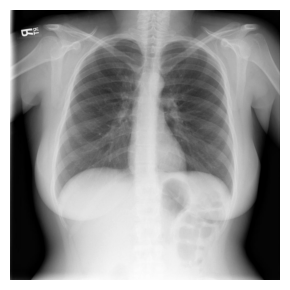

What abnormal findings do you see in this chest X-ray?

Model response:
Based on the provided chest X-ray, I don't see any obvious or significant abnormal findings. The heart size appears within normal limits, the mediastinum is unremarkable, and the lungs are clear without evidence of consolidation, effusions, or masses. The bony structures are also intact.

However, it's important to note that this is a single image and a full interpretation requires clinical context, comparison with prior images if available, and consideration of the patient's symptoms and history.



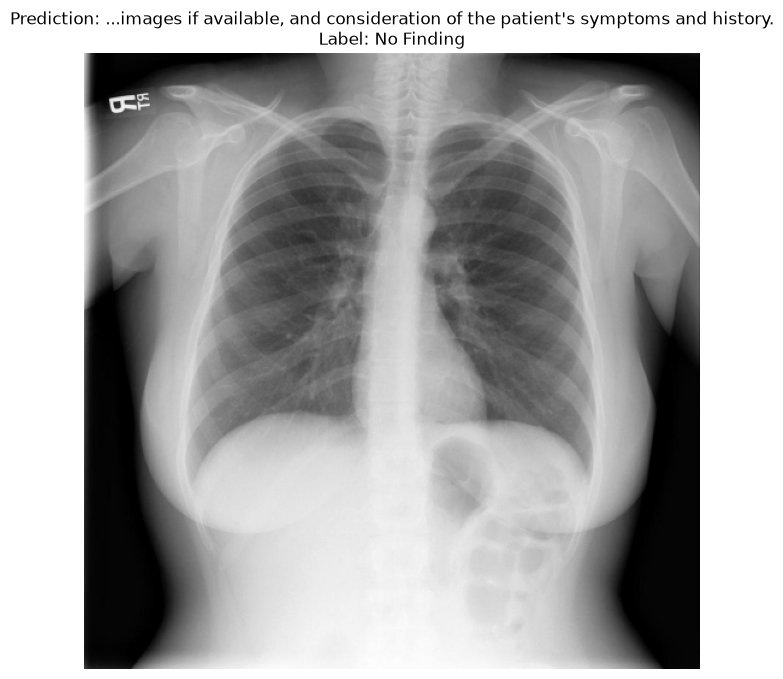

In [5]:
prompt = "What abnormal findings do you see in this chest X-ray?"

example = examples_eval[10]  # you can select other sample
messages = zeroshot.format_data(
    example, "Cardiomegaly", prompt
)  # The condition is not used when you give a prompt
print_prompt(messages)

output = pipe(
    text=messages, max_new_tokens=300, return_full_text=False
)  # Open answers are longer than yes/no
print(f"Model response:\n{output[0]['generated_text'].strip()}\n")
display_prediction(output, example, figsize=(8, 8))

### Classification with Yes/No Questions
Now we use yes/no questions to classify the images. We ask about 4 conditions: Atelectasis, Cardiomegaly, Consolidation, and Pleural Effusion. So each image gets 4 questions (100 images × 4 = 400 questions). This is slow on a T4. To make it faster, use a smaller `n_per_class` in Step 4.

Example: for a Cardiomegaly image, the correct answers are "yes" for Cardiomegaly and "no" for the other 3. For a No Finding image, all 4 answers are "no".

**Score: F1** for each condition, and the **macro F1** (the mean of the F1 scores). F1 is from 0 to 1, and higher is better. F1 is high only if the model finds most true cases and most of its "yes" answers are correct. The papers use 5 conditions and other datasets (MIMIC-CXR and CheXpert), so you cannot compare our F1 with the papers.

The next cell:
1. Runs the model and reads each answer: "yes", "no", or "invalid" (no "Final Answer" found). The code is in `utils/vqa.py`. It calls `pipe` with `zeroshot.format_data` for each question.
2. Shows the F1 scores.
3. Shows the yes-rate table.

In [6]:
# ---- 1. Run the model on all questions, and read the answers
print(
    f"🔄 Evaluating zero-shot prompting on {len(examples_eval)} images x {len(CONDITIONS)} conditions..."
)
results_zeroshot = run_yes_no(pipe, zeroshot, examples_eval, CONDITIONS)

# ---- 2. F1 table
metrics_zeroshot = binary_metrics(results_zeroshot)
print("\n📊 Zero-Shot Results:")
print("=" * 30)
print(f"Macro F1: {metrics_zeroshot.loc['Macro average', 'F1']:.3f}")
print(
    f"Invalid answers: {(results_zeroshot['Prediction'] == 'invalid').sum()}/{len(results_zeroshot)}"
)
display(metrics_zeroshot.round(2))

# ---- 3. Error analysis: the yes-rate table
print("\n📊 Yes-rate table:")
display(yes_rate_table(results_zeroshot).round(2))

🔄 Evaluating zero-shot prompting on 100 images x 4 conditions...


Progress: 100%|██████████| 20/20 [01:12<00:00,  3.64s/it]


📊 Zero-Shot Results:
Macro F1: 0.558
Invalid answers: 0/400



The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.


,Positives,TP,FN,FP,TN,Invalid,Sensitivity,Specificity,F1
Atelectasis,20,14,6,34,46,0,0.70,0.57,0.41
Cardiomegaly,20,16,4,12,68,0,0.80,0.85,0.67
Consolidation,20,6,14,1,79,0,0.30,0.99,0.44
Pleural Effusion,20,11,9,0,80,0,0.55,1.00,0.71
Macro average,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,0.59,0.85,0.56



📊 Yes-rate table:


Condition,Atelectasis,Cardiomegaly,Consolidation,Pleural Effusion
Pathology,,,,
No Finding,0.05,0.20,0.00,0.00
Atelectasis,0.70,0.10,0.00,0.00
Cardiomegaly,0.30,0.80,0.00,0.00
Consolidation,0.45,0.15,0.30,0.00
Pleural Effusion,0.90,0.15,0.05,0.55


#### Error Analysis
The **yes-rate table** above shows how often the model says **yes**. The rows are the true classes, and the columns are the questions.
- Where the row and the column are the same class, the value should be high. This is the sensitivity: how often the model finds the condition.
- All other values should be low. A high value shows false positives: the model says "yes", but the condition is not there.

Example: a high value in row "Pleural Effusion", column "Atelectasis" means that the model often says "yes" to atelectasis for effusion images. This is not a surprise, because the two often occur together.

## Step 7: Report Generation
MedGemma can also **write a radiology report**. Open-i has the radiologist's report for each study, so we can compare the two.

We use the prompt from the [MedGemma paper](https://arxiv.org/abs/2507.05201) (Table A7): the image, then `<INDICATION> findings:`. The model then writes the findings.

**Differences from the paper:**
- The paper used the pretrained MedGemma 1 model. This model is not trained to follow instructions. MedGemma 1.5 has only the instruction-tuned model ("-it"), so we use it.
- We keep our system prompt ("You are an expert radiologist."). The paper used none.
- The model often writes an IMPRESSION section too. We keep only the findings (`extract_findings` in `utils/report.py`).

**Score the reports:** here we compare the reports by eye. To score them with code, you can use a report metric. Two examples (there are many others):
- [RadGraph](https://github.com/Stanford-AIMI/radgraph): finds the clinical findings and their relations in a report. **RadGraph F1** compares them with the true report. The MedGemma papers use this score.
- [CRIMSON](https://arxiv.org/abs/2603.06183): uses an LLM to score a report. Errors that are more important for the patient get a larger penalty.

> ⚠️ Generated reports are for research and education only. Do not use them for patient care.

### Report Generation Example
The next cell makes the prompt for one image, generates the findings, and compares them with the true findings.

Some indications look like "XXXX-year-old male with chest pain", because Open-i replaces private details with "XXXX".

CONVERSATION PROMPT

[SYSTEM]
----------------------------------------
You are an expert radiologist.

[USER]
----------------------------------------
  📷 PIL Image - Mode: RGB, Size: 512x420
XXXX-year-old male with chest pain findings:

🔄 Generating report...


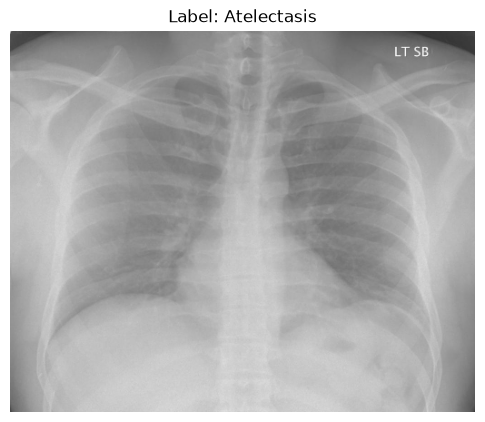

📋 INDICATION: XXXX-year-old male with chest pain

🤖 GENERATED (MedGemma)
------------------------------------------------------------
The lungs are clear without focal consolidation, pleural effusion, or pneumothorax. The
cardiomediastinal silhouette is normal. The osseous structures are intact.

📝 TRUE (radiologist)
------------------------------------------------------------
Low lung volumes. Cardiac and mediastinal contours are unremarkable. Pulmonary vascularity is within
normal limits. No focal air space opacities, pleural effusion, or pneumothorax. Mild left lingular
platelike atelectasis. XXXX are grossly unremarkable.


In [7]:
# ---- 1. Functions to make the prompt and generate the report
def format_report_prompt(example, prompt=None):
    """Make the messages to generate findings for one image. Default prompt: "<INDICATION> findings:"."""
    if prompt is None:
        indication = example.get("Indication")
        has_indication = isinstance(indication, str) and indication.strip()
        prompt = f"{indication} findings:" if has_indication else "findings:"
    return [
        SYSTEM_MESSAGE,
        {
            "role": "user",
            "content": [
                {
                    "type": "image",
                    "image": preprocess(Image.open(example["ImagePath"])),
                },
                {"type": "text", "text": prompt},
            ],
        },
    ]


def generate_report(example, prompt=None, max_new_tokens=300):
    """Generate a report for one image. Return the full generated text."""
    output = pipe(
        text=format_report_prompt(example, prompt),
        max_new_tokens=max_new_tokens,  # Reports are longer than yes/no answers
        return_full_text=False,
    )
    return output[0]["generated_text"].strip()


# ---- 2. Generate the findings for one image
example = examples_eval[56]
print_prompt(format_report_prompt(example), show_images=False)

print("🔄 Generating report...")
report = generate_report(example)

display_report(example, extract_findings(report), example["Findings"])

### Try your own report prompt
Ideas:
- Remove the indication. Use only "findings:".
- Ask for a full report: "Write a radiology report for this chest X-ray. Use two sections: FINDINGS and IMPRESSION."
- Ask the model to describe the heart, lungs, pleura, and bones one at a time.

The next cell uses the second idea, so it compares the result with the full true report.

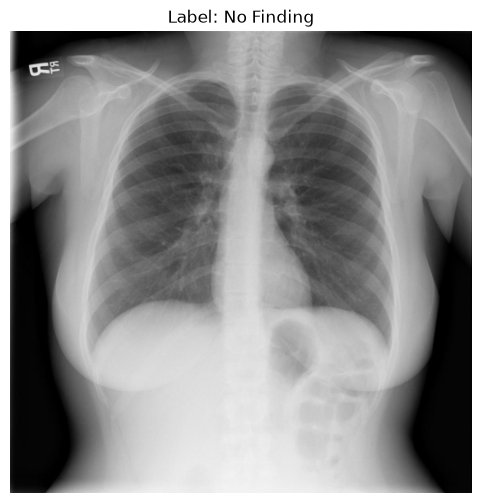

📋 INDICATION: XXXX-year-old woman with XXXX.

🤖 GENERATED (MedGemma)
------------------------------------------------------------
FINDINGS:
The heart size is normal. The mediastinal and hilar contours are normal. The lungs are clear without
focal consolidation, pleural effusion, or pneumothorax. The visualized osseous structures are
unremarkable. IMPRESSION:
Normal chest X-ray.

📝 TRUE (radiologist)
------------------------------------------------------------
Heart size, mediastinal contour, and pulmonary vascularity are within normal limits. No focal
consolidation, pleural effusion, or pneumothorax is identified. No acute osseous abnormality
identified. No acute cardiopulmonary abnormality. .


In [8]:
my_prompt = "Write a radiology report for this chest X-ray. Use two sections: FINDINGS and IMPRESSION."

example = examples_eval[10]  # you can select other sample
report = generate_report(example, prompt=my_prompt)
display_report(example, report, example["Report"])

## Step 8: Anatomy Localization
MedGemma 1.5 can also **find a body part** in a chest X-ray. It gives a **bounding box** (a rectangle) around it, and our code draws the box. This is new in 1.5. On the model card, the box overlap score (IoU, 0–100) went from 3.1 (MedGemma 1) to 38.0 (MedGemma 1.5).

We use the steps from Google's [anatomy localization notebook](https://github.com/Google-Health/medgemma/blob/main/notebooks/cxr_anatomy_localization_with_hugging_face.ipynb):
- **Prompt:** asks "Where is the {object}?" and explains the box format. A box is `[y0, x0, y1, x1]` (y comes first), with values from 0 to 1000. The prompt also says that "left" means the patient's left.
- **Image:** we add black borders to make it square. The box values are for this square image.
- **Thinking:** the model first writes its thinking (the text between `<unused94>` and `<unused95>`). Then it gives the answer. We remove the thinking and keep the answer.

> ⏱️ Each object takes a long time, because the model first writes about 500 tokens of thinking.

### Localization Example
The next cell asks for 4 body parts in one image and draws the boxes. It asks one body part at a time. Each time, `<OBJECT>` in the prompt becomes the name of the body part.

Instructions:
The following user query will require outputting bounding boxes. The format of bounding boxes coordinates is [y0, x0, y1, x1] where (y0, x0) must be top-left corner and (y1, x1) the bottom-right corner. This implies that x0 < x1 and y0 < y1. Always normalize the x and y coordinates the range [0, 1000], meaning that a bounding box starting at 15% of the image width would be associated with an x coordinate of 150. You MUST output a single parseable json list of objects enclosed into ```json...``` brackets, for instance ```json[{"box_2d": [800, 3, 840, 471], "label": "car"}, {"box_2d": [400, 22, 600, 73], "label": "dog"}]``` is a valid output. Now answer to the user query.

Remember "left" refers to the patient's left side where the heart is and sometimes underneath an L in the upper right corner of the image.

Query:
Where is the <OBJECT>? Don't give a final answer without reasoning. Output the final answer in the format "Final Answer: X" where X is a JSON list of objects. 

Objects: 100%|██████████| 4/4 [00:55<00:00, 13.77s/it]

Answer for 'right lung':
Final Answer: ```json[{"box_2d": [170, 160, 830, 520], "label": "right lung"}]```

Answer for 'left lung':
Final Answer: X```json
[
  {"box_2d": [170, 520, 830, 870], "label": "left lung"}
]
```

Answer for 'cardiac silhouette':
Final Answer: ```json[{"box_2d": [430, 380, 820, 720], "label": "cardiac silhouette"}]```

Answer for 'right clavicle':
Final Answer: ```json[{"box_2d": [125, 105, 310, 460], "label": "right clavicle"}]```



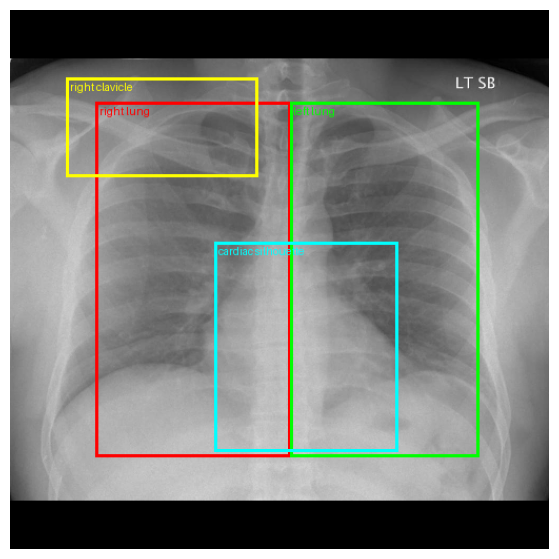

In [9]:
# ---- 1. Make the prompt and the square image
def localize(image, object_name, max_new_tokens=1000):
    """Ask MedGemma for the box of one object. Return (boxes, answer text without the thinking trace)."""
    messages = [
        SYSTEM_MESSAGE,
        {
            "role": "user",
            "content": [
                {"type": "image", "image": image},
                {"type": "text", "text": localization_prompt(object_name)},
            ],
        },
    ]
    output = pipe(text=messages, max_new_tokens=max_new_tokens, return_full_text=False)
    response = output[0]["generated_text"]
    return parse_boxes(response), remove_thinking(response)


example = examples_eval[56]
image = pad_to_square(preprocess(Image.open(example["ImagePath"])))
print(localization_prompt("<OBJECT>"))  # <OBJECT> becomes each body part below

# ---- 2. Find 4 body parts
# Options: body part names from Chest ImaGenome, the box data that MedGemma 1.5 learned from
# - Add "right" or "left": lung, upper lung zone, mid lung zone, lower lung zone, apical zone,
#   hilar structures, costophrenic angle, cardiophrenic angle, hemidiaphragm, clavicle, upper abdomen
# - No side: trachea, carina, spine, mediastinum, upper mediastinum, aortic arch, svc,
#   cardiac silhouette, cavoatrial junction, right atrium, descending aorta, abdomen
objects = ["right lung", "left lung", "cardiac silhouette", "right clavicle"]

all_boxes = []
answers = {}
for name in tqdm(objects, desc="Objects"):
    boxes, answers[name] = localize(image, name)
    all_boxes += [
        {"box_2d": b["box_2d"], "label": name} for b in boxes[:1]
    ]  # Keep the first box for each object

for name, answer in answers.items():
    print(f"Answer for '{name}':\n{answer}\n")
draw_boxes(image, all_boxes)

### Try your own object
Change the object or the image, and run the cell again. The comment in the cell above lists the body part names.

Ideas: "trachea", "aortic arch", "left costophrenic angle", "right hilar structures", "left clavicle".

Final Answer: ```json[{"box_2d": [160, 420, 410, 570], "label": "trachea"}]```


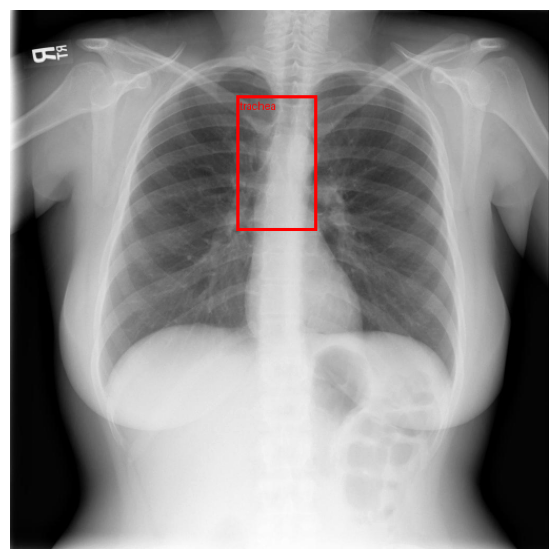

In [10]:
my_object = "trachea"

example = examples_eval[10]  # you can select other sample
image = pad_to_square(preprocess(Image.open(example["ImagePath"])))
boxes, answer = localize(image, my_object)
print(answer)
draw_boxes(image, [{"box_2d": b["box_2d"], "label": my_object} for b in boxes])

## Step 9: Summary
**What we did:**
- ✅ **VQA and classification:** we asked yes/no questions with the prompt from the MedGemma papers, and scored 4 conditions on 100 images with F1.
- ✅ **Report generation:** MedGemma wrote the findings, and we compared them with the radiologist's findings.
- ✅ **Anatomy localization:** MedGemma found body parts and gave a box for each one.

**Key points:**
- The "Final Answer: yes/no" format makes the answers easy to read with code.
- A report can read well and still be wrong. Look for **normal bias**: does the model write "the lungs are clear" for an abnormal image?
- MedGemma 1.5 gives much better boxes than MedGemma 1, but check them by eye. A box can be in the correct place and still have the wrong size.

**Limitations:**
- ❌ We used only a few images. With other images, the results can change.
- ❌ The model sees only one frontal image. It has no lateral view and no prior exam.
- ❌ We did not compute the clinical scores from the papers (RadGraph F1 for reports, IoU for boxes). For report scores, see the links in Step 7.

## Step 10 (Bonus): Web App
A web app lets you use the model without code. Here we use **Gradio** (a Python library for simple web apps) to make a small app with 3 tabs: VQA, report generation, and anatomy localization. Pick an Open-i image from the list, or upload your own chest X-ray. All 3 tabs use this image. For an Open-i image, the report tab also shows the true findings, so you can compare them with the generated findings.

The app uses the model and the functions from the steps above. Before you start the app, run the cells in Steps 1, 3, 4, and 5. Then run the first example cell in Steps 6, 7, and 8 (VQA, report generation, and localization). You do not need the classification cell.

The next cell installs Gradio (if needed), builds the app, and starts it. The app code is in `utils/app.py`.
- To stop the app, run `demo.close()`.
- In Colab, the app uses a **public link** (`share=True`). Without it, Colab cannot show the images in the app. The link is random, and it stops when you stop the runtime. But anyone with the link can use your model, so do not share the link.

> ⏱️ The app runs one request at a time. Localization is slow, because the model writes its thinking first.

In [ ]:
# ---- 1. Install Gradio (if needed)
try:
    import gradio
except ImportError:
    !pip install -q gradio

from utils.app import make_app

# ---- 2. Build and start the app (in Colab, it shows below this cell)
demo = make_app(pipe, examples_eval, SYSTEM_MESSAGE, localize)
# Colab needs a public link (share=True). Without it, the images do not show.
# allowed_paths lets Gradio show the Open-i images.
demo.launch(share=IN_COLAB, allowed_paths=[DATA_DIR])